In [4]:
import pandas as pd

df = pd.read_csv("../data/processed/online_retail_propre.csv",
                 parse_dates=["InvoiceDate"])

clients = (df.groupby("CustomerID")
             .agg(premier_achat=("InvoiceDate", "min"),
                  nb_commandes=("InvoiceNo", "nunique"),
                  ca_total=("CA", "sum"))
             .reset_index())

n_avant = len(df)
df_m = df.merge(clients, on="CustomerID", how="left",
                validate="m:1", indicator=True)

print(n_avant, "→", len(df_m))
print(df_m["_merge"].value_counts())

C:\Users\andya\AppData\Local\Temp\ipykernel_14408\3534649900.py:3: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/processed/online_retail_propre.csv",


524876 → 524876
_merge
both          524876
left_only          0
right_only         0
Name: count, dtype: int64


CA mensuel

InvoiceDate
2010-12-01     821452.73
2011-01-01     612628.01
2011-02-01     522545.56
2011-03-01     716215.26
2011-04-01     536968.49
2011-05-01     769296.61
2011-06-01     760547.01
2011-07-01     718076.12
2011-08-01     757841.38
2011-09-01    1056435.19
2011-10-01    1151263.73
2011-11-01    1503866.78
2011-12-01     469320.73
Freq: MS, Name: CA, dtype: float64


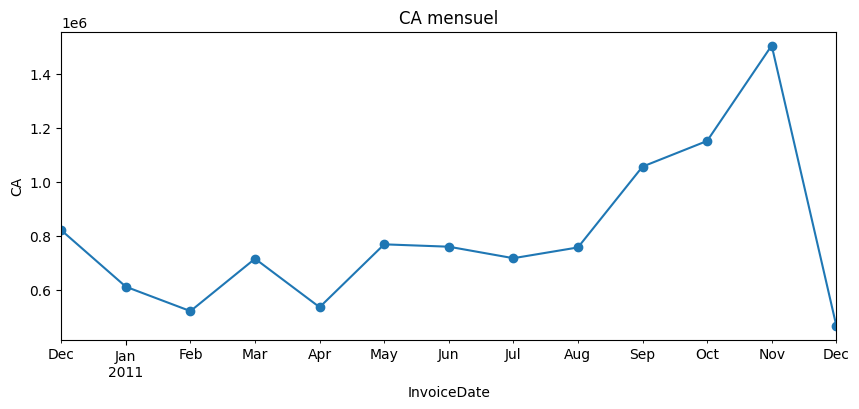

In [17]:
import matplotlib.pyplot as plt

mensuel = df_m.set_index("InvoiceDate").resample("MS")["CA"].sum()
print(mensuel)

mensuel.plot(kind="line", marker="o", figsize=(10, 4),
             title="CA mensuel")
plt.ylabel("CA")
plt.show()

In [10]:
cont = {
    "Europe": ["United Kingdom", "France", "Germany", "EIRE", "Spain",
               "Netherlands", "Belgium", "Switzerland", "Portugal", "Italy",
               "Norway", "Finland", "Sweden", "Austria", "Denmark", "Poland",
               "Iceland", "Greece", "Malta", "Lithuania", "Czech Republic",
               "Cyprus", "Channel Islands", "European Community"],
    "Amérique du Nord": ["USA", "Canada"],
    "Amérique du Sud": ["Brazil"],
    "Océanie": ["Australia"],
    "Asie": ["Japan", "Hong Kong", "Singapore", "Israel", "Lebanon",
             "Bahrain", "United Arab Emirates", "Saudi Arabia"],
    "Afrique": ["RSA"],
    "Inconnu": ["Unspecified"],
}

continents = pd.DataFrame(
    [(pays, c) for c, pays in cont.items() for pays in pays],
    columns=["Country", "Continent"],
)

n_avant = len(df)
df_m = df.merge(continents, on="Country", how="left",
                validate="m:1", indicator=True)

print(n_avant, "→", len(df_m))
print(df_m["_merge"].value_counts())

524876 → 524876
_merge
both          524876
left_only          0
right_only         0
Name: count, dtype: int64


In [12]:
import os
import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)
ordre = ["Monday", "Tuesday", "Wednesday", "Thursday",
         "Friday", "Saturday", "Sunday"]
df_m["jour"] = df_m["InvoiceDate"].dt.day_name()
df_m["heure"] = df_m["InvoiceDate"].dt.hour

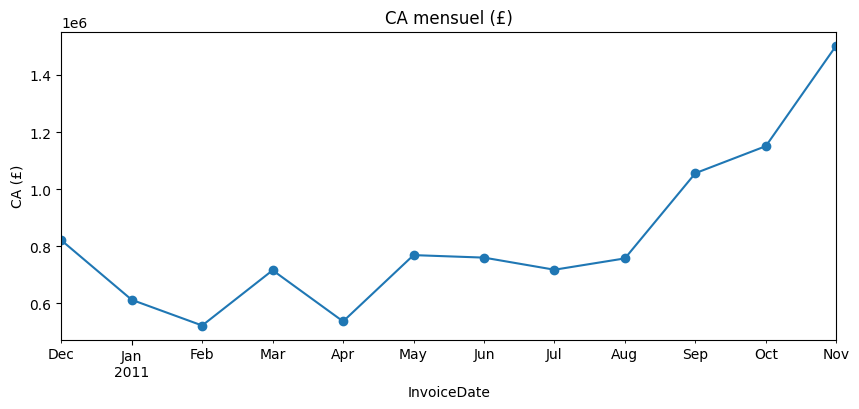

In [13]:
mensuel = df_m.set_index("InvoiceDate").resample("MS")["CA"].sum()
mensuel = mensuel[mensuel.index < "2011-12-01"]

mensuel.plot(marker="o", figsize=(10, 4), title="CA mensuel (£)")
plt.ylabel("CA (£)")
plt.savefig("../figures/ca_mensuel.png", dpi=150, bbox_inches="tight")
plt.show()

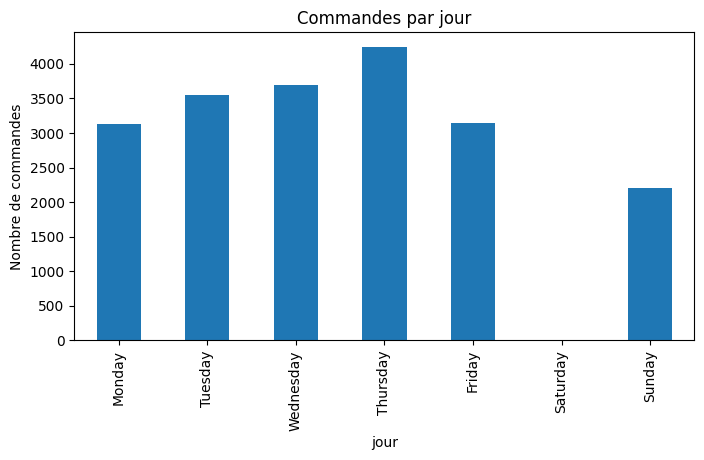

In [14]:
(df_m.groupby("jour")["InvoiceNo"].nunique()
     .reindex(ordre)
     .plot(kind="bar", figsize=(8, 4), title="Commandes par jour"))
plt.ylabel("Nombre de commandes")
plt.savefig("../figures/commandes_jour.png", dpi=150, bbox_inches="tight")
plt.show()

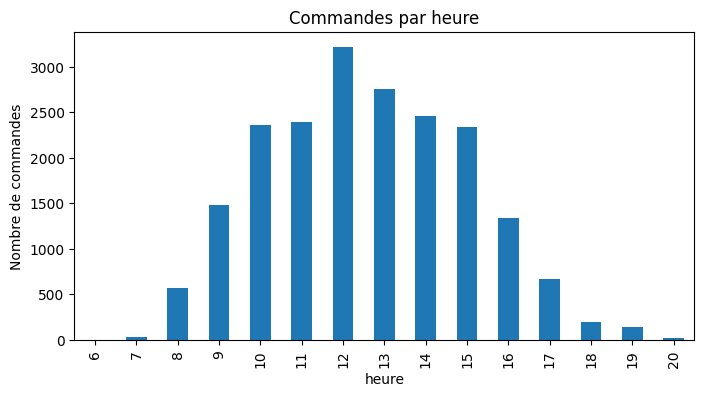

In [15]:
(df_m.groupby("heure")["InvoiceNo"].nunique()
     .plot(kind="bar", figsize=(8, 4), title="Commandes par heure"))
plt.ylabel("Nombre de commandes")
plt.savefig("../figures/commandes_heure.png", dpi=150, bbox_inches="tight")
plt.show()

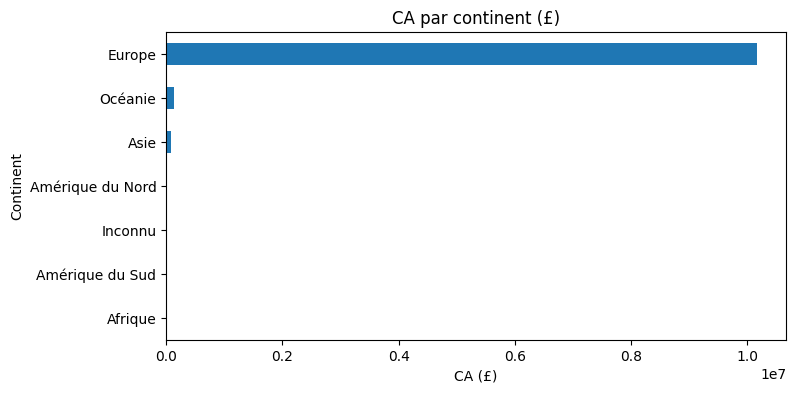

In [16]:
(df_m.groupby("Continent")["CA"].sum()
     .sort_values()
     .plot(kind="barh", figsize=(8, 4), title="CA par continent (£)"))
plt.xlabel("CA (£)")
plt.savefig("../figures/ca_continent.png", dpi=150, bbox_inches="tight")
plt.show()